In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# Load the feature-engineered dataset

df = pd.read_csv(
    "C:/Users/telvi/Downloads/AMDARI/Nexora_Care_Flow/data/processed_data/AppointmentRecords_feature_eng.csv"
)

In [3]:
# Display the first five rows

df.head()

,AppointmentDateTime,appointment_volume,is_holiday,day_of_week
0,2024-01-01,31,1,0
1,2024-01-02,221,0,1
2,2024-01-03,167,0,2
3,2024-01-04,171,0,3
4,2024-01-05,103,0,4


In [4]:
# Inspect the dataset
# Display information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   AppointmentDateTime  731 non-null    object
 1   appointment_volume   731 non-null    int64 
 2   is_holiday           731 non-null    int64 
 3   day_of_week          731 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 23.0+ KB


In [5]:
# Display summary statistics for the numerical columns and catigorical features

df.describe(include='all')

,AppointmentDateTime,appointment_volume,is_holiday,day_of_week
count,731,731.000000,731.000000,731.000000
unique,731,NaN,NaN,NaN
top,2024-01-01,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,176.953488,0.035568,2.991792
std,NaN,93.651119,0.185337,2.002037
min,NaN,7.000000,0.000000,0.000000
25%,NaN,108.500000,0.000000,1.000000
50%,NaN,197.000000,0.000000,3.000000
75%,NaN,249.500000,0.000000,5.000000


In [6]:
# Display the number of unique values in each column

df.nunique()

AppointmentDateTime    731
appointment_volume     271
is_holiday               2
day_of_week              7
dtype: int64

In [7]:
# Convert AppointmentDateTime from text to datetime format

df["AppointmentDateTime"] = pd.to_datetime(
    df["AppointmentDateTime"]
)

# Display the data types

df.dtypes

AppointmentDateTime    datetime64[ns]
appointment_volume              int64
is_holiday                      int64
day_of_week                     int64
dtype: object

In [8]:
# Set AppointmentDateTime as the index

daily_appointment = df.set_index(
    "AppointmentDateTime"
)

# Sort the data chronologically
# Set the date as the index
# My data is already daily, so we do not group or aggregate it again.

daily_appointment = daily_appointment.sort_index()

# Display the first five rows

daily_appointment.head()

,appointment_volume,is_holiday,day_of_week
AppointmentDateTime,,,
2024-01-01,31,1,0
2024-01-02,221,0,1
2024-01-03,167,0,2
2024-01-04,171,0,3
2024-01-05,103,0,4


In [9]:
# Validate the time series
# First check for missing values:
daily_appointment.isnull().sum()

appointment_volume    0
is_holiday            0
day_of_week           0
dtype: int64

In [10]:
# Display the first and last dates

print("Start date:", daily_appointment.index.min())
print("End date:", daily_appointment.index.max())

Start date: 2024-01-01 00:00:00
End date: 2025-12-31 00:00:00


In [11]:
# Then check the target:
# Display summary statistics for appointment volume

daily_appointment["appointment_volume"].describe()

count    731.000000
mean     176.953488
std       93.651119
min        7.000000
25%      108.500000
50%      197.000000
75%      249.500000
max      406.000000
Name: appointment_volume, dtype: float64

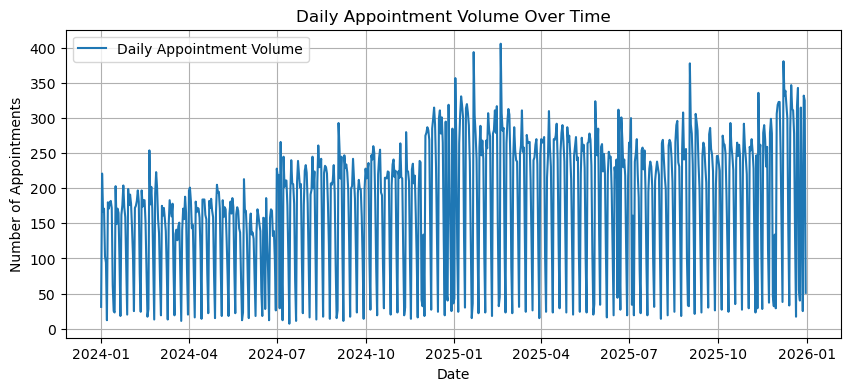

In [12]:
# Visualise daily appointment volume
# Plot daily appointment volume over time

plt.figure(figsize=(10, 4))

plt.plot(
    daily_appointment.index,
    daily_appointment["appointment_volume"],
    label="Daily Appointment Volume"
)

plt.title("Daily Appointment Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")
plt.legend()
plt.grid(True)

plt.show()

# Analyse appointment volume by day of week

Now we investigate the day_of_week feature that you already created.
Remember: 0 = Monday, 1 = Tuesday, 2 = Wednesday, 3 = Thursday, 4 = Friday, 5 = Saturday, 6 = Sunday

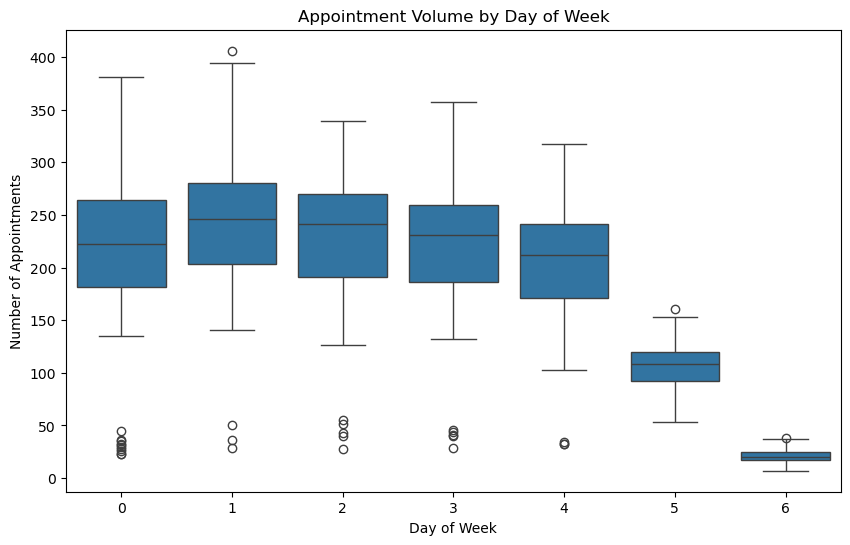

In [13]:
# box plot to compare the distribution of appointment volumes across the seven days.
# Create a box plot of appointment volume by day of week

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=daily_appointment,
    x="day_of_week",
    y="appointment_volume"
)

plt.title("Appointment Volume by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Appointments")

plt.show()

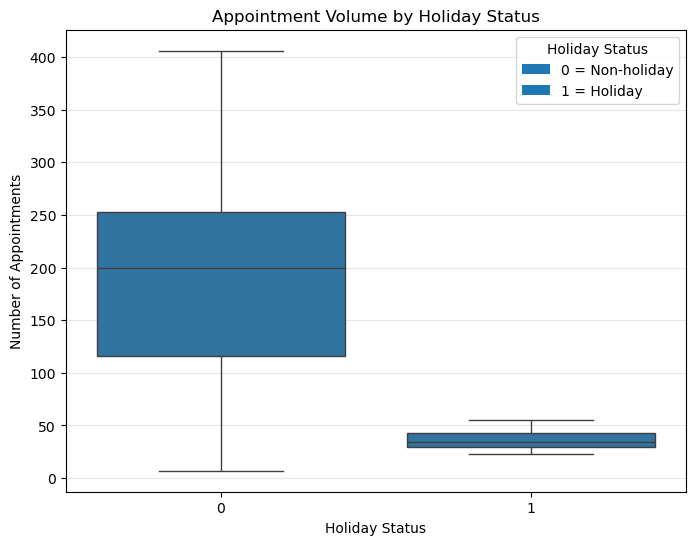

In [14]:
# Analyse appointment volume by holiday status

plt.figure(figsize=(8, 6))

sns.boxplot(
    data=daily_appointment,
    x="is_holiday",
    y="appointment_volume"
)

# Add a legend to explain the holiday codes

from matplotlib.patches import Patch

plt.legend(
    handles=[
        Patch(label="0 = Non-holiday"),
        Patch(label="1 = Holiday")
    ],
    title="Holiday Status"
)

plt.title("Appointment Volume by Holiday Status")
plt.xlabel("Holiday Status")
plt.ylabel("Number of Appointments")

plt.grid(axis="y", alpha=0.3)

plt.show()

# Prepare the target and existing features

In [15]:
# Define the target variable

target = "appointment_volume"

# Define the existing features

features = [
    "is_holiday",
    "day_of_week"
]

# Display the selected variables

print("Target:", target)
print("Features:", features)

Target: appointment_volume
Features: ['is_holiday', 'day_of_week']


# Create the chronological train/test split

We will reserve the final 8 weeks (56 days) for testing.

In [16]:
# Number of weeks reserved for testing

test_weeks = 8

# Convert weeks to days

test_size = test_weeks * 7

In [17]:
# Check that there are enough observations

if len(daily_appointment) <= test_size:
    raise ValueError(
        "There are not enough observations for the selected test period."
    )

In [18]:
# Training data contains all observations before the final 56 days

train = daily_appointment.iloc[:-test_size].copy()

# Testing data contains the final 56 days

test = daily_appointment.iloc[-test_size:].copy()

# Display the number of observations

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 675
Testing observations: 56


In [19]:
# Display the training period

print("\nTraining period:")
print("Start:", train.index.min())
print("End:  ", train.index.max())

# Display the testing period

print("\nTesting period:")
print("Start:", test.index.min())
print("End:  ", test.index.max())


Training period:
Start: 2024-01-01 00:00:00
End:   2025-11-05 00:00:00

Testing period:
Start: 2025-11-06 00:00:00
End:   2025-12-31 00:00:00


In [20]:
# Confirm that the split is chronological

print(
    "\nChronological split:",
    train.index.max() < test.index.min()
)

# Confirm that there is no date overlap

print(
    "No date overlap:",
    train.index.intersection(test.index).empty
)


Chronological split: True
No date overlap: True


# Naive baseline
The purpose of the Naive Baseline is to establish a simple benchmark. We predict that each future day's appointment volume will be the same as the previous day's appointment volume.

This gives us a baseline against which the more advanced models can be compared.

In [21]:
# Create the Naive predictions
# Naive Baseline
# Predict each day's appointment volume using
# the appointment volume from the previous day.

naive_predictions = (
    daily_appointment["appointment_volume"]
    .shift(1)
    .loc[test.index]
)

# Display the first five predictions

naive_predictions.head()

AppointmentDateTime
2025-11-06    270.0
2025-11-07    253.0
2025-11-08    228.0
2025-11-09    103.0
2025-11-10     23.0
Name: appointment_volume, dtype: float64

For example, if the previous day had 200 appointments, the prediction for the next day will be 200.

In [22]:
# Create a results table
# Combine the actual and predicted appointment volumes

naive_results = pd.DataFrame({
    "Actual": test["appointment_volume"],
    "NaivePrediction": naive_predictions
})

# Remove any missing predictions

naive_results = naive_results.dropna()

# Display the first five results

naive_results.head()

,Actual,NaivePrediction
AppointmentDateTime,,
2025-11-06,253,270.0
2025-11-07,228,253.0
2025-11-08,103,228.0
2025-11-09,23,103.0
2025-11-10,247,23.0


In [23]:
# Define a function to calculate MAE and RMSE

def evaluate(actual, predicted, model_name):
    
    mae = mean_absolute_error(
        actual,
        predicted
    )
    
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )
    
    print(
        f"{model_name} - MAE: {mae:.2f}, RMSE: {rmse:.2f}"
    )
    
    return {
        "label": model_name,
        "mae": mae,
        "rmse": rmse
    }

In [24]:
# Calculate MAE and RMSE
# Evaluate the Naive Baseline

naive_score = evaluate(
    naive_results["Actual"],
    naive_results["NaivePrediction"],
    "Naive_Baseline"
)

naive_score

Naive_Baseline - MAE: 113.34, RMSE: 152.89


{'label': 'Naive_Baseline',
 'mae': 113.33928571428571,
 'rmse': np.float64(152.8855197291658)}

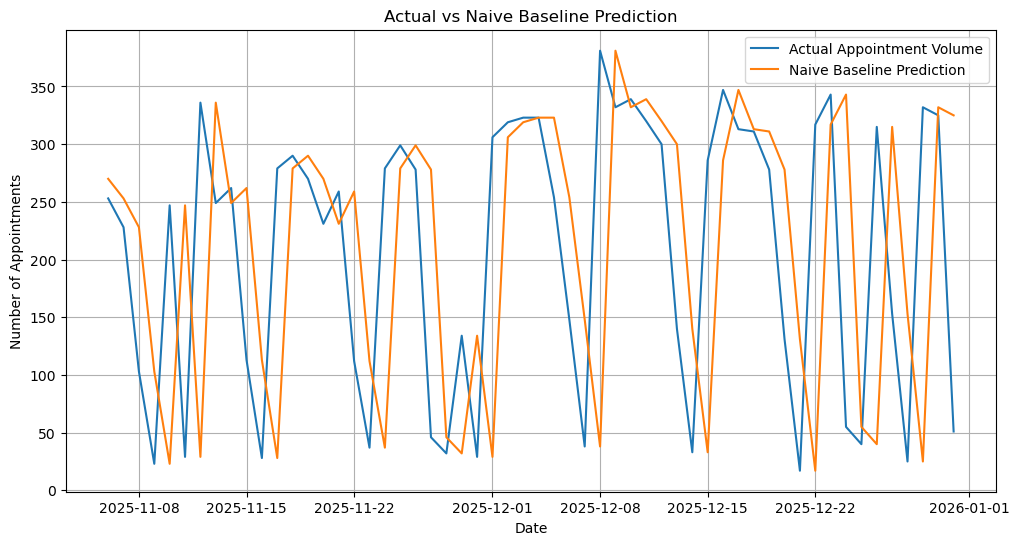

In [25]:
# Plot actual versus Naive Baseline predictions

plt.figure(figsize=(12,6))

plt.plot(
    naive_results.index,
    naive_results["Actual"],
    label="Actual Appointment Volume"
)

plt.plot(
    naive_results.index,
    naive_results["NaivePrediction"],
    label="Naive Baseline Prediction"
)

plt.title("Actual vs Naive Baseline Prediction")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")

plt.legend()
plt.grid(True)

plt.show()

# Interpretation
MAE = 113.34 means that, on average, the Naive Baseline's prediction was approximately 113 appointments away from the actual daily volume.
RMSE = 152.89 indicates that some prediction errors were considerably larger, particularly around the sharp peaks and drops visible in your plot.
The fact that RMSE is substantially higher than MAE suggests that large errors occur on some days.

In [26]:
# Seasonal Naive Baseline
# our data shows a strong recurring weekly pattern, the next baseline should use the appointment volume from 7 days earlier.
# Seasonal Naive Baseline
# Predict each day using the appointment volume
# from the same day of the previous week.

naive_seasonal_baseline = (
    daily_appointment["appointment_volume"]
    .shift(7)
    .loc[test.index]
)

In [27]:
# Combine actual and predicted values

seasonal_naive_results = pd.DataFrame({
    "Actual": test["appointment_volume"],
    "SeasonalNaivePrediction": naive_seasonal_baseline
})

# Remove missing predictions

seasonal_naive_results = seasonal_naive_results.dropna()

# Display the first five predictions

seasonal_naive_results.head()

,Actual,SeasonalNaivePrediction
AppointmentDateTime,,
2025-11-06,253,243.0
2025-11-07,228,220.0
2025-11-08,103,116.0
2025-11-09,23,29.0
2025-11-10,247,259.0


In [28]:
# Evaluate the Seasonal Naive Baseline

seasonal_naive_score = evaluate(
    seasonal_naive_results["Actual"],
    seasonal_naive_results["SeasonalNaivePrediction"],
    "Seasonal_Naive_Baseline"
)

seasonal_naive_score

Seasonal_Naive_Baseline - MAE: 51.46, RMSE: 95.35


{'label': 'Seasonal_Naive_Baseline',
 'mae': 51.464285714285715,
 'rmse': np.float64(95.35216680435592)}

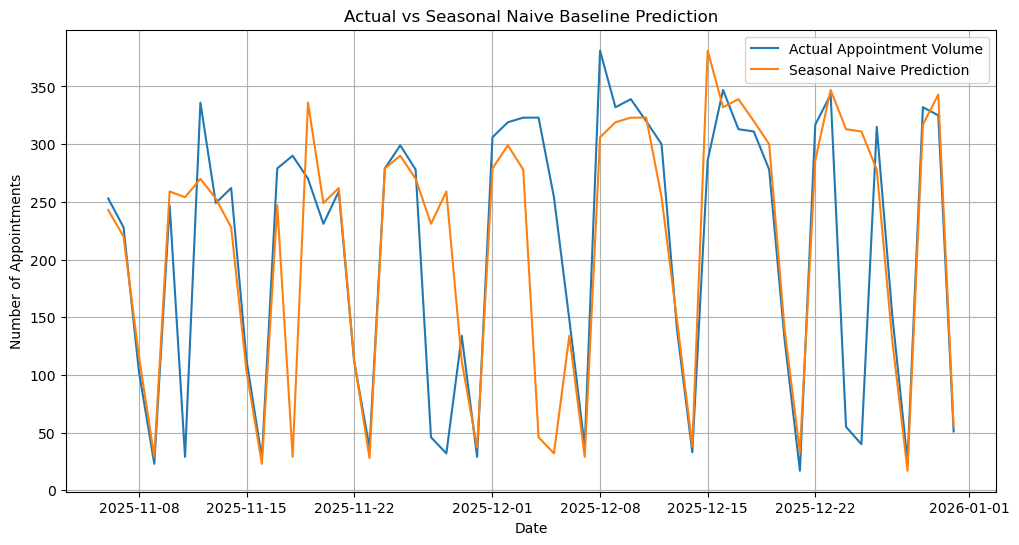

In [29]:
# Plot actual versus Seasonal Naive predictions

plt.figure(figsize=(12, 6))

plt.plot(
    seasonal_naive_results.index,
    seasonal_naive_results["Actual"],
    label="Actual Appointment Volume"
)

plt.plot(
    seasonal_naive_results.index,
    seasonal_naive_results["SeasonalNaivePrediction"],
    label="Seasonal Naive Prediction"
)

plt.title("Actual vs Seasonal Naive Baseline Prediction")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")

plt.legend()
plt.grid(True)

plt.show()

The Seasonal Naive baseline achieved an MAE of 51.46 and an RMSE of 95.35, substantially outperforming the standard Naive baseline, which achieved an MAE of 113.34 and an RMSE of 152.89. The improvement demonstrates that using the appointment volume from the corresponding day of the previous week provides more accurate predictions than relying solely on the previous day's volume. This result provides evidence of a recurring weekly pattern in appointment demand and establishes a strong benchmark for evaluating the subsequent forecasting models

# Model training

In [30]:
# SARIMAX
# Train the SARIMAX model
# SARIMAX is particularly important for this project because it can incorporate our existing variables:
# is_holiday
# day_of_week
# It can also explicitly model the weekly seasonal structure

sarimax_model = SARIMAX(
    train[target],
    exog=train[features],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit the model

sarimax_fit = sarimax_model.fit(
    disp=False
)

# Display the model summary

print(sarimax_fit.summary())

c:\Users\telvi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\telvi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                appointment_volume   No. Observations:                  675
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -3006.689
Date:                           Thu, 10 Sep 2026   AIC                           6027.378
Time:                                   20:18:27   BIC                           6058.802
Sample:                               01-01-2024   HQIC                          6039.560
                                    - 11-05-2025                                         
Covariance Type:                             opg                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
is_holiday   -215.4659      2.815    -76.546      0.000    -220.983    -209.949
day_of_week    -0.0063   4251.976  -1.48

In [31]:
# Generate SARIMAX predictions for the test period

sarimax_predictions = sarimax_fit.get_forecast(
    steps=len(test),
    exog=test[features]
).predicted_mean

# Create a results dataframe

sarimax_results = pd.DataFrame({
    "Actual": test[target],
    "SARIMAXPrediction": sarimax_predictions
})

# Display the first five predictions

sarimax_results.head()

,Actual,SARIMAXPrediction
2025-11-06,253,250.248739
2025-11-07,228,223.836077
2025-11-08,103,117.759132
2025-11-09,23,27.742153
2025-11-10,247,249.980075


In [32]:
# Evaluate the SARIMAX model

sarimax_score = evaluate(
    sarimax_results["Actual"],
    sarimax_results["SARIMAXPrediction"],
    "SARIMAX"
)

sarimax_score

SARIMAX - MAE: 33.09, RMSE: 44.12


{'label': 'SARIMAX',
 'mae': 33.08822208133052,
 'rmse': np.float64(44.12046696578756)}

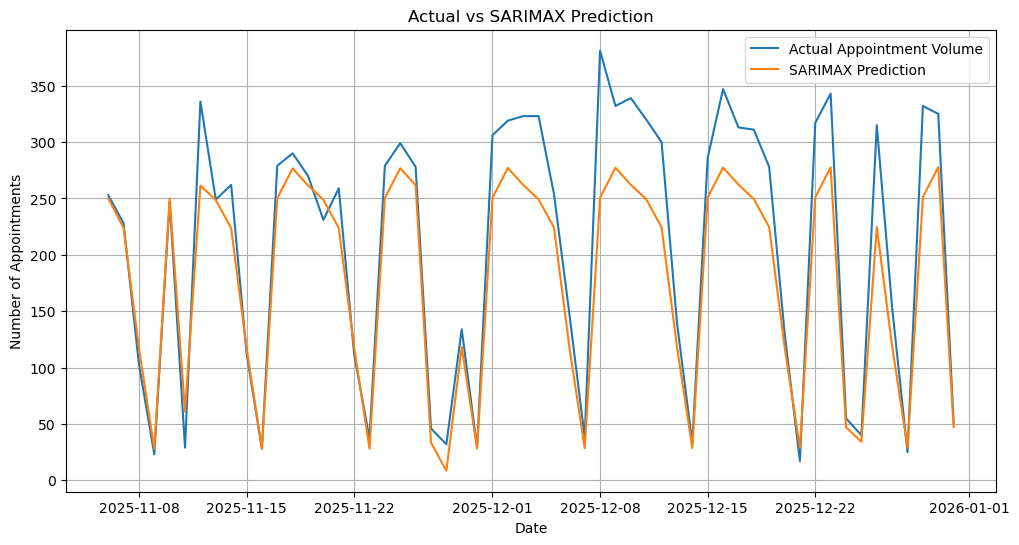

In [33]:
# Plot actual versus SARIMAX predictions

plt.figure(figsize=(12, 6))

plt.plot(
    sarimax_results.index,
    sarimax_results["Actual"],
    label="Actual Appointment Volume"
)

plt.plot(
    sarimax_results.index,
    sarimax_results["SARIMAXPrediction"],
    label="SARIMAX Prediction"
)

plt.title("Actual vs SARIMAX Prediction")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")

plt.legend()
plt.grid(True)

plt.show()

# ARIMA
Unlike XGBoost, ARIMA does not use is_holiday or day_of_week as predictors in this basic version. It models the historical appointment-volume series itself.

In [34]:
# Train the ARIMA model

arima_model = ARIMA(
    train[target],
    order=(1, 1, 1)
)

# Fit the model

arima_fit = arima_model.fit()

# Display the model summary

print(arima_fit.summary())

c:\Users\telvi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\telvi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\telvi\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:     appointment_volume   No. Observations:                  675
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -3943.625
Date:                Thu, 10 Sep 2026   AIC                           7893.250
Time:                        20:18:28   BIC                           7906.789
Sample:                    01-01-2024   HQIC                          7898.493
                         - 11-05-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2816      0.033      8.566      0.000       0.217       0.346
ma.L1         -0.9844      0.007   -142.702      0.000      -0.998      -0.971
sigma2      7044.1576    484.946     14.526      0.0

In [35]:
# Generate ARIMA predictions for the test period

arima_predictions = arima_fit.forecast(
    steps=len(test)
)

# Create a results dataframe

arima_results = pd.DataFrame({
    "Actual": test[target],
    "ARIMAPrediction": arima_predictions
})

# Display the first five predictions

arima_results.head()

,Actual,ARIMAPrediction
2025-11-06,253,218.224775
2025-11-07,228,203.644536
2025-11-08,103,199.538646
2025-11-09,23,198.382401
2025-11-10,247,198.056795


In [36]:
# Evaluate the ARIMA model

arima_score = evaluate(
    arima_results["Actual"],
    arima_results["ARIMAPrediction"],
    "ARIMA"
)

arima_score

ARIMA - MAE: 110.85, RMSE: 119.31


{'label': 'ARIMA',
 'mae': 110.85351116626683,
 'rmse': np.float64(119.30936122331798)}

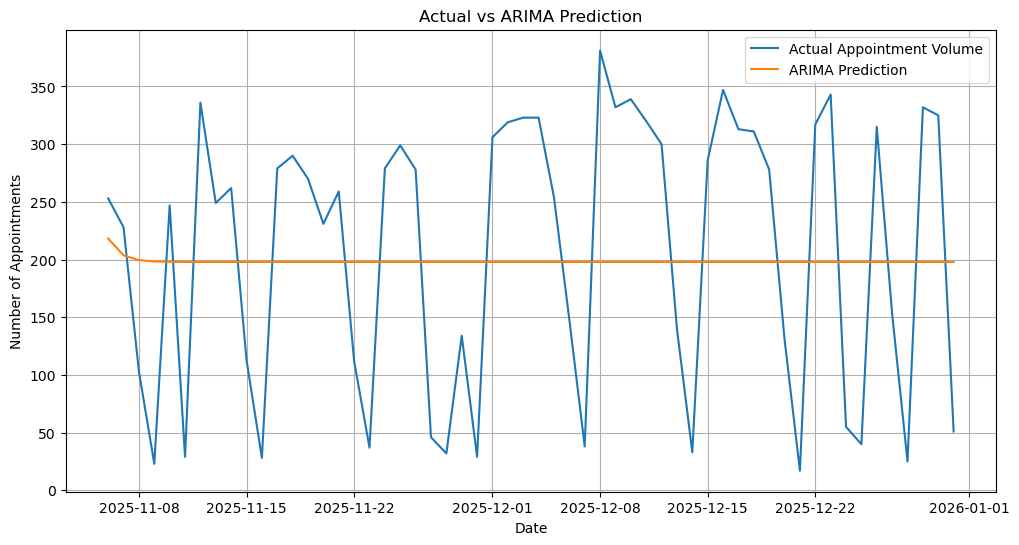

In [37]:
# Plot actual versus ARIMA predictions

plt.figure(figsize=(12, 6))

plt.plot(
    arima_results.index,
    arima_results["Actual"],
    label="Actual Appointment Volume"
)

plt.plot(
    arima_results.index,
    arima_results["ARIMAPrediction"],
    label="ARIMA Prediction"
)

plt.title("Actual vs ARIMA Prediction")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")

plt.legend()
plt.grid(True)

plt.show()

# Prophet
Prophet uses the date as the time variable and the appointment volume as the target.
# Prepare Prophet data

Prophet requires the columns to be called ds and y.

In [38]:
# Prepare the training data for Prophet

prophet_train = train.reset_index()[[
    "AppointmentDateTime",
    "appointment_volume"
]].copy()

# Rename the columns required by Prophet

prophet_train.columns = [
    "ds",
    "y"
]

# Display the first five rows

prophet_train.head()

,ds,y
0,2024-01-01,31
1,2024-01-02,221
2,2024-01-03,167
3,2024-01-04,171
4,2024-01-05,103


In [39]:
# Train Prophet
# Create the Prophet model

prophet_model = Prophet(
    weekly_seasonality=True,
    daily_seasonality=False,
    yearly_seasonality=True
)

# Fit the Prophet model

prophet_model.fit(prophet_train)

20:18:29 - cmdstanpy - INFO - Chain [1] start processing
20:18:31 - cmdstanpy - INFO - Chain [1] done processing


In [40]:
# Generate predictions
# Create the future dates for the test period

prophet_future = test.reset_index()[[
    "AppointmentDateTime"
]].copy()

# Rename the date column

prophet_future.columns = ["ds"]

# Generate predictions

prophet_forecast = prophet_model.predict(
    prophet_future
)

# Create a results dataframe

prophet_results = pd.DataFrame({
    "Actual": test[target].values,
    "ProphetPrediction": prophet_forecast["yhat"].values
}, index=test.index)

# Display the first five predictions

prophet_results.head()

,Actual,ProphetPrediction
AppointmentDateTime,,
2025-11-06,253,239.767419
2025-11-07,228,218.067007
2025-11-08,103,117.838219
2025-11-09,23,31.486881
2025-11-10,247,213.538895


In [41]:
# Evaluate the Prophet model

prophet_score = evaluate(
    prophet_results["Actual"],
    prophet_results["ProphetPrediction"],
    "Prophet"
)

prophet_score

Prophet - MAE: 56.41, RMSE: 81.42


{'label': 'Prophet',
 'mae': 56.408270622541245,
 'rmse': np.float64(81.41865375299707)}

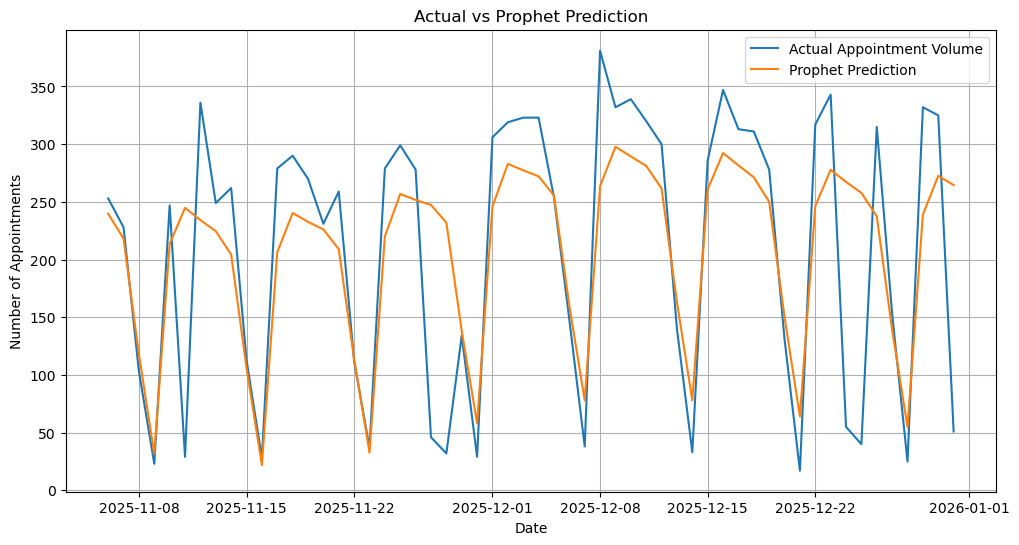

In [42]:
# plot prophet
# Plot actual versus Prophet predictions

plt.figure(figsize=(12, 6))

plt.plot(
    prophet_results.index,
    prophet_results["Actual"],
    label="Actual Appointment Volume"
)

plt.plot(
    prophet_results.index,
    prophet_results["ProphetPrediction"],
    label="Prophet Prediction"
)

plt.title("Actual vs Prophet Prediction")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")

plt.legend()
plt.grid(True)

plt.show()

# XGBoost
XGBoost will use the two existing predictors:

is_holiday
day_of_wee
We will not create additional lag or rolling features.

In [43]:
# Define XGBoost variables
# Define the training and testing variables for XGBoost

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

# Display the shapes of the datasets

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (675, 2)
X_test: (56, 2)
y_train: (675,)
y_test: (56,)


In [44]:
# Train XGBoost
# Train the XGBoost regression model

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    objective="reg:squarederror"
)

# Fit the model

xgb_model.fit(
    X_train,
    y_train
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [45]:
# Generate XGBoost predictions

xgb_predictions = xgb_model.predict(
    X_test
)

# Create a results dataframe

xgb_results = pd.DataFrame({
    "Actual": test[target],
    "XGBoostPrediction": xgb_predictions
}, index=test.index)

# Display the first five predictions

xgb_results.head()

,Actual,XGBoostPrediction
AppointmentDateTime,,
2025-11-06,253,226.818878
2025-11-07,228,205.540985
2025-11-08,103,104.406471
2025-11-09,23,20.636120
2025-11-10,247,224.275925


In [46]:
# Evaluate the XGBoost model

xgb_score = evaluate(
    xgb_results["Actual"],
    xgb_results["XGBoostPrediction"],
    "XGBoost"
)

xgb_score

XGBoost - MAE: 49.22, RMSE: 62.31


{'label': 'XGBoost',
 'mae': 49.21580123901367,
 'rmse': np.float64(62.31194559996602)}

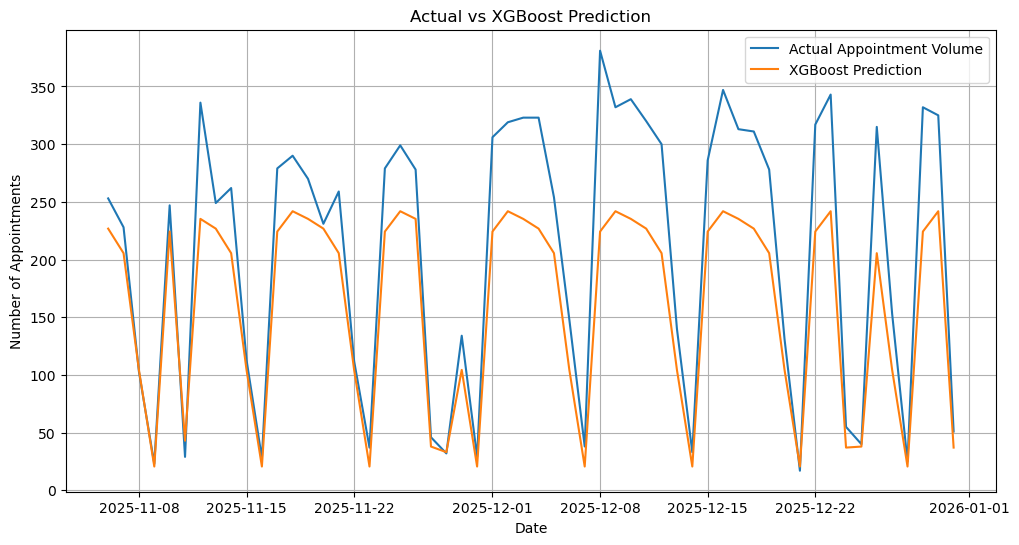

In [47]:
# Plot actual versus XGBoost predictions

plt.figure(figsize=(12, 6))

plt.plot(
    xgb_results.index,
    xgb_results["Actual"],
    label="Actual Appointment Volume"
)

plt.plot(
    xgb_results.index,
    xgb_results["XGBoostPrediction"],
    label="XGBoost Prediction"
)

plt.title("Actual vs XGBoost Prediction")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")

plt.legend()
plt.grid(True)

plt.show()